In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('titanic_dataset.csv')
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


### Q1. Create a Bar Chart to show the survival rate of passengers from each Embarked port.

#### X-axis: Embarked
#### Y-axis: Average of Survived
#### Add proper title and labels.
#### Identify which port has the highest survival rate.

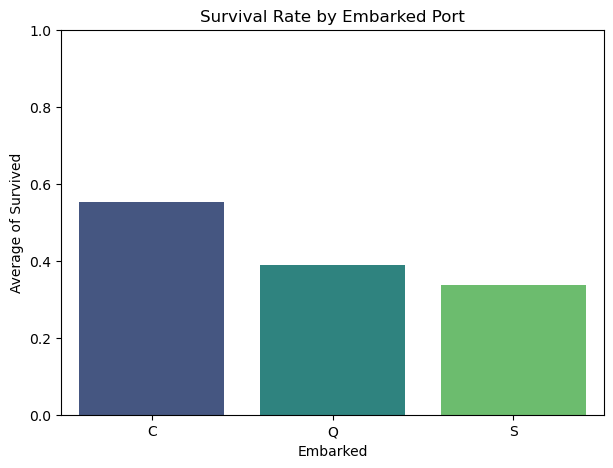

Port with highest survival rate: C (55.36%)


In [4]:
# Group by Embarked and calculate mean survival rate
survival = df.groupby('Embarked')['Survived'].mean().reset_index()

# Plotting
plt.figure(figsize=(7, 5))
sns.barplot(x='Embarked', y='Survived', data=survival, palette='viridis')
plt.title('Survival Rate by Embarked Port')
plt.xlabel('Embarked')
plt.ylabel('Average of Survived')
plt.ylim(0, 1)
plt.show()

# Identify highest survival rate port
highest_port = survival.sort_values(by='Survived', ascending=False).iloc[0]
print(f"Port with highest survival rate: {highest_port['Embarked']} ({highest_port['Survived']:.2%})")

### Q2. Create a new column FamilySize using:

#### FamilySize = SibSp + Parch + 1

#### Then create a Count Plot showing the number of passengers for each family-size category.

#### X-axis: FamilySize
#### Y-axis: Number of Passengers
#### Identify the most common family size.

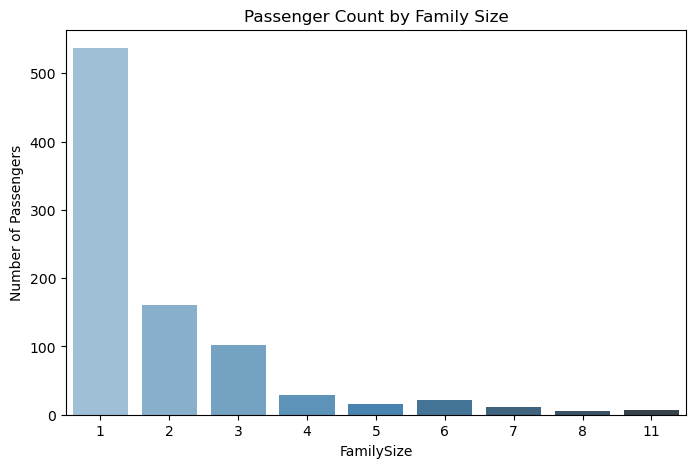

Most common family size: 1 (Count: 537)


In [5]:
# Create FamilySize
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1

# Plotting
plt.figure(figsize=(8, 5))
sns.countplot(x='FamilySize', data=df, palette='Blues_d')
plt.title('Passenger Count by Family Size')
plt.xlabel('FamilySize')
plt.ylabel('Number of Passengers')
plt.show()

# Identify most common family size
most_common = df['FamilySize'].mode()[0]
count_most_common = (df['FamilySize'] == most_common).sum()
print(f"Most common family size: {most_common} (Count: {count_most_common})")

### Q3. Create a Box Plot to compare Fare across different Pclass, while separating passengers by Sex.

#### X-axis: Pclass
#### Y-axis: Fare
#### Use Sex as hue.
#### Identify which group paid the highest fares.

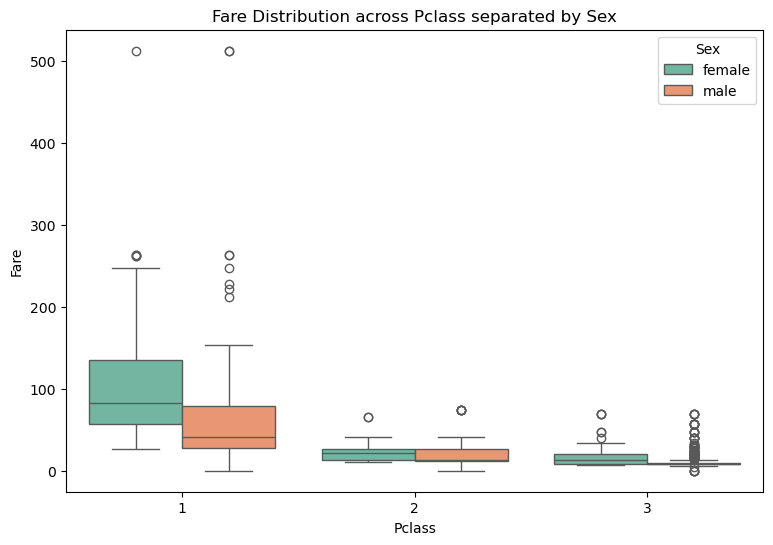

                 median        mean       max
Pclass Sex                                   
1      female  82.66455  106.125798  512.3292
       male    41.26250   67.226127  512.3292
2      female  22.00000   21.970121   65.0000
       male    13.00000   19.741782   73.5000
3      female  12.47500   16.118810   69.5500
       male     7.92500   12.661633   69.5500


In [6]:
plt.figure(figsize=(9, 6))
sns.boxplot(x='Pclass', y='Fare', hue='Sex', data=df, palette='Set2')
plt.title('Fare Distribution across Pclass separated by Sex')
plt.xlabel('Pclass')
plt.ylabel('Fare')
plt.show()

#  breakdown to confirm top group
fare_summary = df.groupby(['Pclass', 'Sex'])['Fare'].agg(['median', 'mean', 'max'])
print(fare_summary)

### Q4. Using the FamilySize column created in Q2, create a Line Plot showing the average survival rate for each family size.

#### X-axis: FamilySize
#### Y-axis: Survival Rate
#### Add markers to the line.
#### Identify the family size with the highest survival rate.

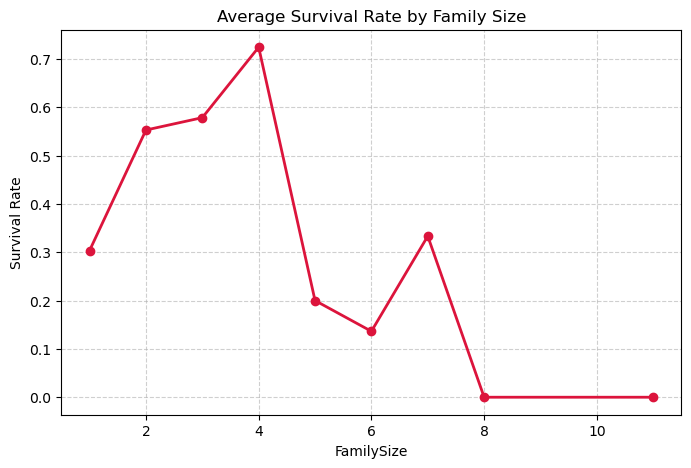

Highest survival rate family size: 4 (72.41%)


In [7]:
#  survival rate per family size
fam_survival = df.groupby('FamilySize')['Survived'].mean().reset_index()

# Plotting
plt.figure(figsize=(8, 5))
plt.plot(fam_survival['FamilySize'], fam_survival['Survived'], marker='o', color='crimson', linewidth=2)
plt.title('Average Survival Rate by Family Size')
plt.xlabel('FamilySize')
plt.ylabel('Survival Rate')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

#  highest survival rate
highest_fam = fam_survival.sort_values(by='Survived', ascending=False).iloc[0]
print(f"Highest survival rate family size: {int(highest_fam['FamilySize'])} ({highest_fam['Survived']:.2%})")

### Q5.Passenger Class & Gender Survival Comparison
#### Create a stacked bar chart showing the number of Survived and Not Survived passengers for each combination of Pclass and Sex.

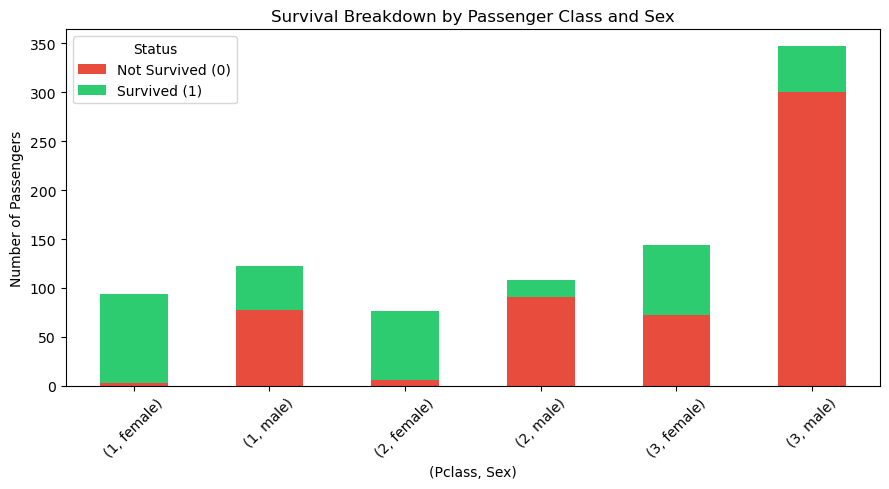

In [8]:
# Cross-tabulate Pclass + Sex vs Survived
survival_crosstab = pd.crosstab([df['Pclass'], df['Sex']], df['Survived'])
survival_crosstab.columns = ['Not Survived (0)', 'Survived (1)']

# Plotting
survival_crosstab.plot(kind='bar', stacked=True, color=['#e74c3c', '#2ecc71'], figsize=(9, 5))
plt.title('Survival Breakdown by Passenger Class and Sex')
plt.xlabel('(Pclass, Sex)')
plt.ylabel('Number of Passengers')
plt.xticks(rotation=45)
plt.legend(title='Status')
plt.tight_layout()
plt.show()